# EDA of the Abalone dataset

Goal: understand which physical measurements help predict the number of rings (age = rings + 1.5 years).

## Imports

In [13]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 500)

## Data

In [14]:
df = pd.read_csv("../data/abalone.csv")
df.head()

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sex             4177 non-null   str    
 1   Length          4177 non-null   float64
 2   Diameter        4177 non-null   float64
 3   Height          4177 non-null   float64
 4   Whole weight    4177 non-null   float64
 5   Shucked weight  4177 non-null   float64
 6   Viscera weight  4177 non-null   float64
 7   Shell weight    4177 non-null   float64
 8   Rings           4177 non-null   int64  
dtypes: float64(7), int64(1), str(1)
memory usage: 297.9 KB


In [16]:
df.describe()

,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
count,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000
mean,0.523992,0.407881,0.139516,0.828742,0.359367,0.180594,0.238831,9.933684
std,0.120093,0.099240,0.041827,0.490389,0.221963,0.109614,0.139203,3.224169
min,0.075000,0.055000,0.000000,0.002000,0.001000,0.000500,0.001500,1.000000
25%,0.450000,0.350000,0.115000,0.441500,0.186000,0.093500,0.130000,8.000000
50%,0.545000,0.425000,0.140000,0.799500,0.336000,0.171000,0.234000,9.000000
75%,0.615000,0.480000,0.165000,1.153000,0.502000,0.253000,0.329000,11.000000
max,0.815000,0.650000,1.130000,2.825500,1.488000,0.760000,1.005000,29.000000


In [17]:
df.isna().sum()

Sex               0
Length            0
Diameter          0
Height            0
Whole weight      0
Shucked weight    0
Viscera weight    0
Shell weight      0
Rings             0
dtype: int64

## Target: number of rings

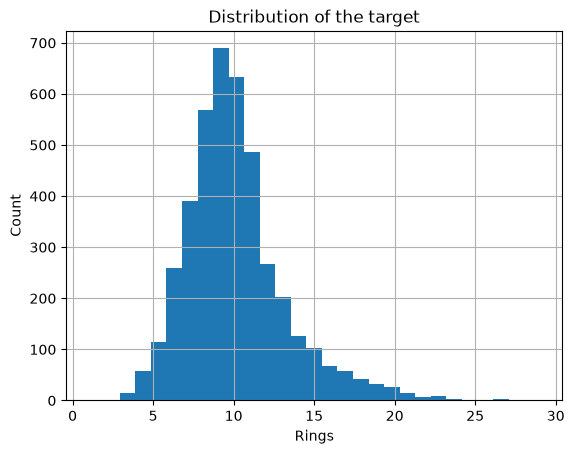

In [18]:
df["Rings"].hist(bins=29)
plt.xlabel("Rings")
plt.ylabel("Count")
plt.title("Distribution of the target")
plt.show()

## Categorical feature: Sex (M, F, I = infant)

In [19]:
df["Sex"].value_counts()

Sex
M    1528
I    1342
F    1307
Name: count, dtype: int64

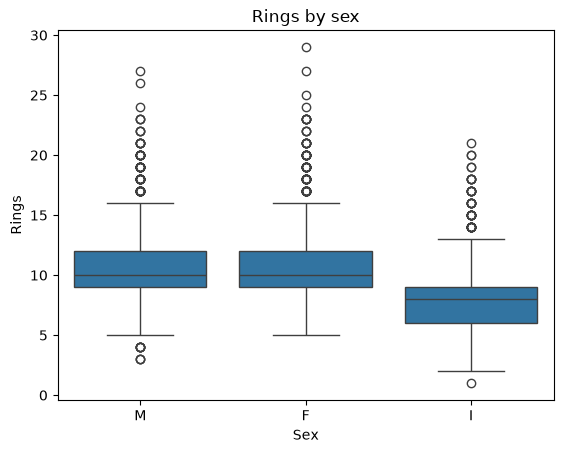

In [20]:
sns.boxplot(data=df, x="Sex", y="Rings")
plt.title("Rings by sex")
plt.show()

## Numerical features

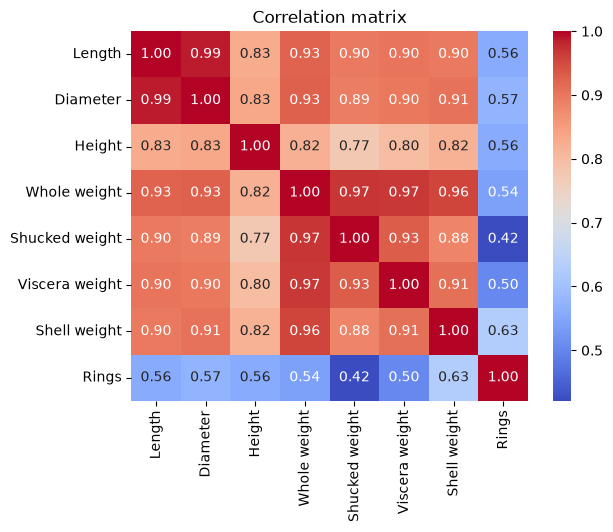

In [21]:
numeric_df = df.drop(columns=["Sex"])
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix")
plt.show()

In [22]:
numeric_df.corr()["Rings"].sort_values(ascending=False)

Rings             1.000000
Shell weight      0.627574
Diameter          0.574660
Height            0.557467
Length            0.556720
Whole weight      0.540390
Viscera weight    0.503819
Shucked weight    0.420884
Name: Rings, dtype: float64

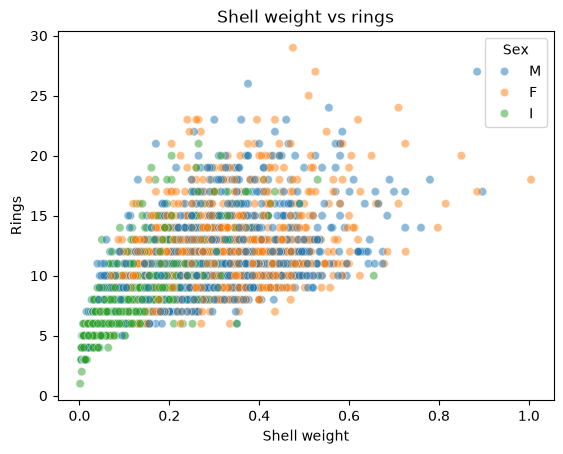

In [23]:
sns.scatterplot(data=df, x="Shell weight", y="Rings", hue="Sex", alpha=0.5)
plt.title("Shell weight vs rings")
plt.show()

In [24]:
df[df["Height"] == 0]

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
1257,I,0.430,0.34,0.0,0.428,0.2065,0.0860,0.1150,8
3996,I,0.315,0.23,0.0,0.134,0.0575,0.0285,0.3505,6


## Conclusions

- No missing values. `Sex` is the only categorical column, so it has to be one-hot encoded.
- The target `Rings` is right-skewed: most abalones have between 5 and 15 rings.
- Every numerical feature is positively correlated with `Rings`. `Shell weight` is the most correlated (0.63), `Shucked weight` the least (0.42).
- The features are very correlated with each other (above 0.9 for most size and weight pairs), so a linear model will predict fine but its coefficients will be hard to interpret.
- Infants (`I`) have clearly fewer rings than adults, so `Sex` carries useful information.
-    - Two rows (both infants) have `Height = 0`, which is physically impossible: these are data errors.